## STEP 1 – LIBRARY IMPORTS

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## STEP 2 – LOADING MASTER DATASET

In [3]:
# Load the CampusBites master dataset

df = pd.read_csv("../data/processed/campusbites_master.csv")

print("Dataset loaded successfully!")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Total Rows: 363
Total Columns: 4


,Shop Name,Item to Buy,Price,Category
0,Annapurna,Plain Idli - 2 pc,40,South Indian
1,Annapurna,Masala Idli - 2 pc,45,South Indian
2,Annapurna,Wada - 2 pc,50,South Indian
3,Annapurna,Plain Dosa,45,South Indian
4,Annapurna,Onion Dosa,50,South Indian


## STEP 3 – DATASET OVERVIEW

In [4]:
# Dataset information

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nCategory Distribution:")
display(df["Category"].value_counts())

print("\nShop Distribution:")
display(df["Shop Name"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 363 entries, 0 to 362
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Shop Name    363 non-null    object
 1   Item to Buy  363 non-null    object
 2   Price        363 non-null    int64 
 3   Category     363 non-null    object
dtypes: int64(1), object(3)
memory usage: 11.5+ KB

Statistical Summary:


,Price
count,363.000000
mean,72.126722
std,42.475153
min,10.000000
25%,50.000000
50%,60.000000
75%,85.000000
max,350.000000



Category Distribution:


Category
Fast Food       111
Beverages        95
South Indian     50
Main Course      42
Desserts         42
Snacks           21
Soups             2
Name: count, dtype: int64


Shop Distribution:


Shop Name
Chai Garam        98
Food Court        82
Frisco            80
Tulips            50
Appetite Rolls    30
Annapurna         23
Name: count, dtype: int64

STEP 4.1 – SHOP-WISE MENU DISTRIBUTION

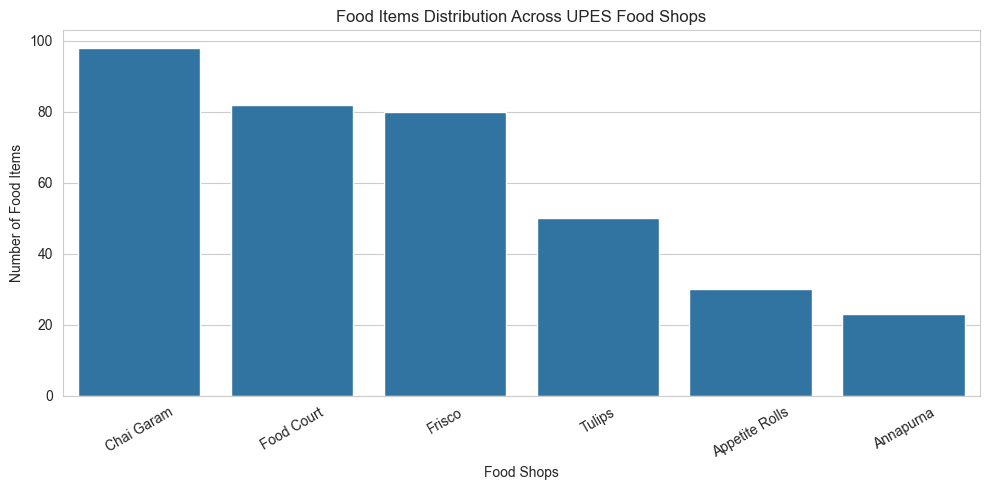

In [5]:
# Count food items available in each shop

shop_counts = df["Shop Name"].value_counts()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=shop_counts.index,
    y=shop_counts.values
)

plt.title("Food Items Distribution Across UPES Food Shops")
plt.xlabel("Food Shops")
plt.ylabel("Number of Food Items")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

STEP 4.2 – FOOD CATEGORY DISTRIBUTION

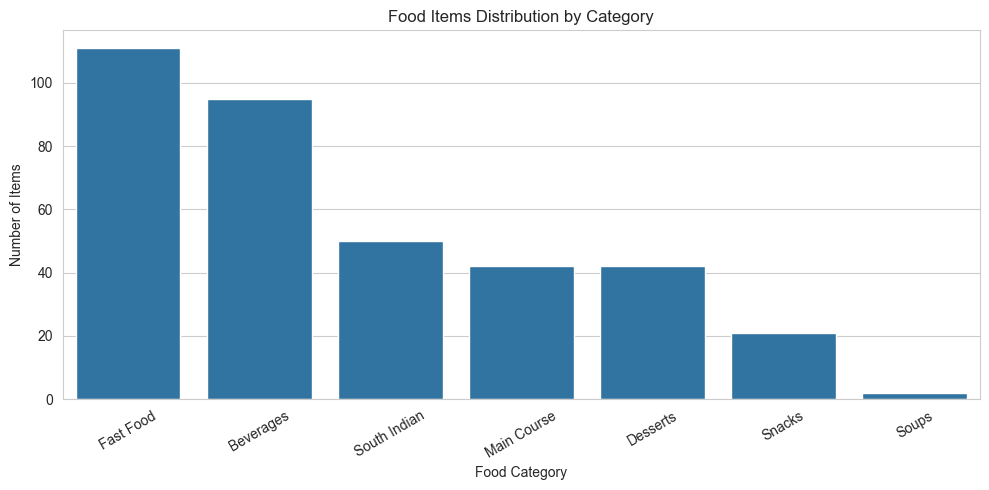

In [6]:
# Count food items in each category

category_counts = df["Category"].value_counts()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)

plt.title("Food Items Distribution by Category")
plt.xlabel("Food Category")
plt.ylabel("Number of Items")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

STEP 4.3 – FOOD PRICE DISTRIBUTION

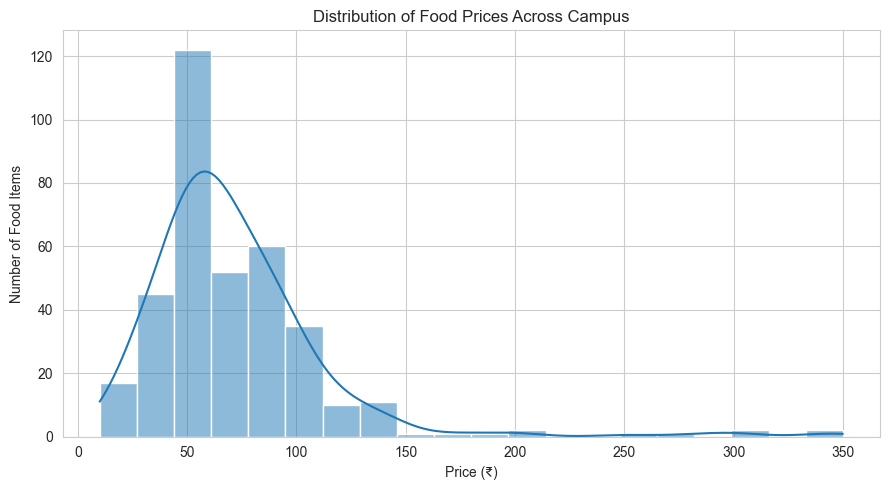

In [7]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Price",
    bins=20,
    kde=True
)

plt.title("Distribution of Food Prices Across Campus")
plt.xlabel("Price (₹)")
plt.ylabel("Number of Food Items")

plt.tight_layout()
plt.show()

STEP 5.1 – SHOP-WISE AVERAGE PRICE COMPARISON

Average Food Price Across Shops:


Shop Name
Tulips            96.460000
Appetite Rolls    94.833333
Frisco            76.250000
Chai Garam        63.163265
Food Court        60.353659
Annapurna         55.434783
Name: Price, dtype: float64

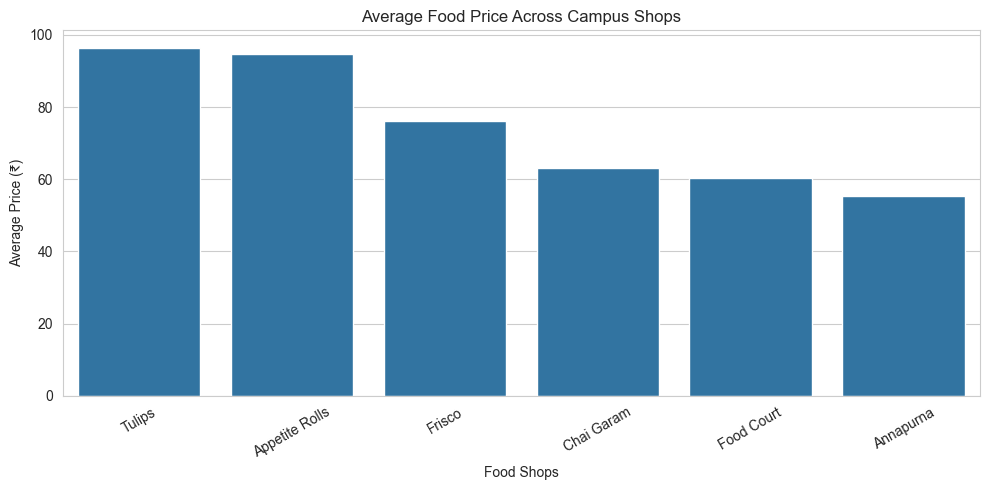

In [8]:
# Calculate average food price for each shop

shop_avg_price = df.groupby("Shop Name")["Price"].mean().sort_values(ascending=False)

print("Average Food Price Across Shops:")
display(shop_avg_price)

# Visualize average prices

plt.figure(figsize=(10, 5))

sns.barplot(
    x=shop_avg_price.index,
    y=shop_avg_price.values
)

plt.title("Average Food Price Across Campus Shops")
plt.xlabel("Food Shops")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

STEP 5.2 – MINIMUM AND MAXIMUM PRICE ANALYSIS

Minimum and Maximum Prices Across Shops:


,min,max
Shop Name,,
Annapurna,40,95
Appetite Rolls,40,150
Chai Garam,20,120
Food Court,10,140
Frisco,20,200
Tulips,20,350


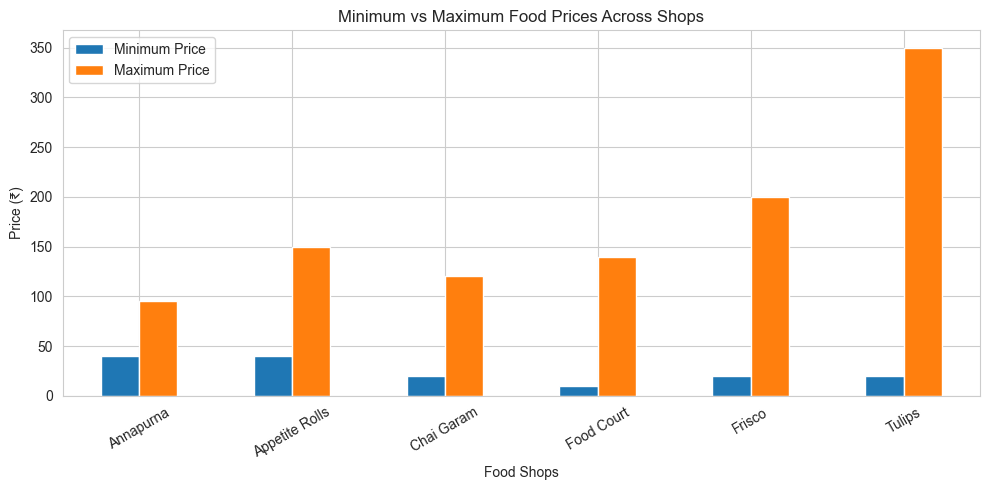

In [9]:
# Find minimum and maximum prices in each shop

price_comparison = df.groupby("Shop Name")["Price"].agg(
    ["min", "max"]
)

print("Minimum and Maximum Prices Across Shops:")
display(price_comparison)

# Visualize the comparison

price_comparison.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Minimum vs Maximum Food Prices Across Shops")
plt.xlabel("Food Shops")
plt.ylabel("Price (₹)")
plt.xticks(rotation=30)
plt.legend(["Minimum Price", "Maximum Price"])

plt.tight_layout()
plt.show()

STEP 5.3 – TOP 10 MOST AFFORDABLE FOOD ITEMS

Top 10 Most Affordable Food Items:


,Shop Name,Item to Buy,Price,Category
189,Food Court,Tandoori Roti (1 pc),10,Main Course
201,Food Court,Samosa,12,Snacks
208,Food Court,Tea,15,Beverages
335,Tulips,Vanilla Cream Roll,20,Fast Food
220,Food Court,Bread Roll,20,Fast Food
282,Frisco,Regular Tea,20,Beverages
58,Chai Garam,Black Coffee - Regular,20,Beverages
231,Food Court,Gulab Jamun,20,Desserts
177,Food Court,Sambhar,20,South Indian
212,Food Court,Coffee,22,Beverages


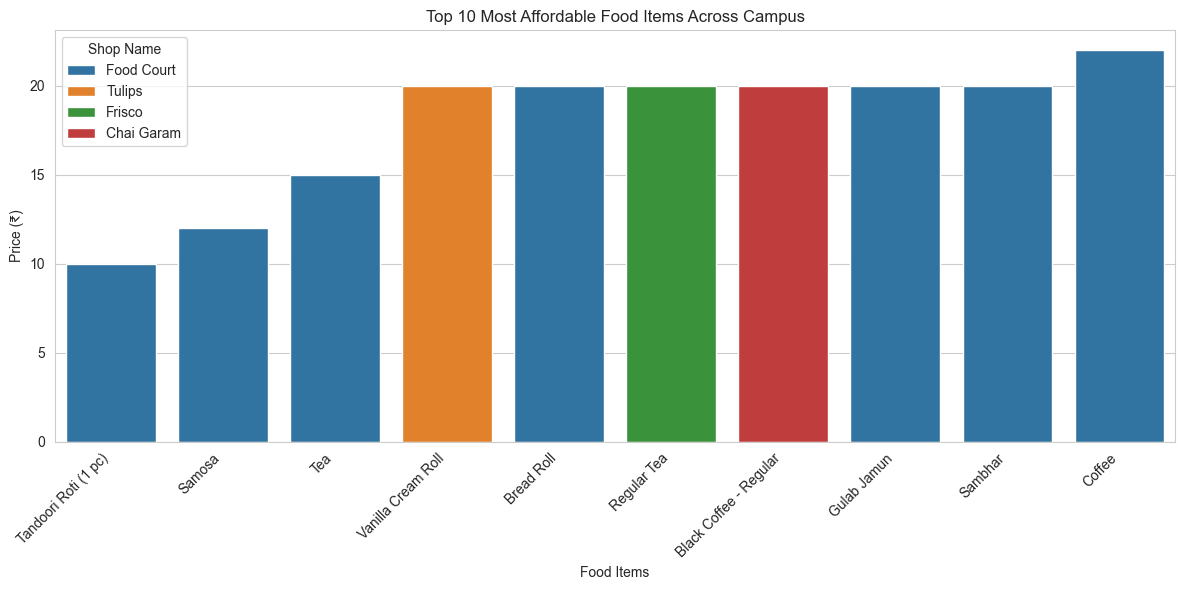

In [10]:
# Find the 10 cheapest food items across campus

cheapest_items = df.sort_values(
    by="Price",
    ascending=True
).head(10)

print("Top 10 Most Affordable Food Items:")
display(cheapest_items)

# Visualize the cheapest items

plt.figure(figsize=(12, 6))

sns.barplot(
    data=cheapest_items,
    x="Item to Buy",
    y="Price",
    hue="Shop Name",
    dodge=False
)

plt.title("Top 10 Most Affordable Food Items Across Campus")
plt.xlabel("Food Items")
plt.ylabel("Price (₹)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

STEP 5.4 – TOP 10 MOST EXPENSIVE FOOD ITEMS

Top 10 Most Expensive Food Items:


,Shop Name,Item to Buy,Price,Category
329,Tulips,Red Velvet (Ice Cream Cake),350,Desserts
330,Tulips,Chocolate (Ice Cream Cake),340,Desserts
333,Tulips,Nutty Belgian Dark Chocolate (Tub),300,Desserts
334,Tulips,Rajwadi Falooda (Tub),300,Beverages
331,Tulips,Butter Scotch (Ice Cream Cake),280,Desserts
332,Tulips,Gauva Chilly (Tub),250,Desserts
251,Frisco,Mexican Paneer Bowl,200,Main Course
252,Frisco,Mexican Chicken Bowl,200,Main Course
269,Frisco,Malai Chicken Wrap,180,Fast Food
328,Tulips,American Nuts (Brick),170,Desserts


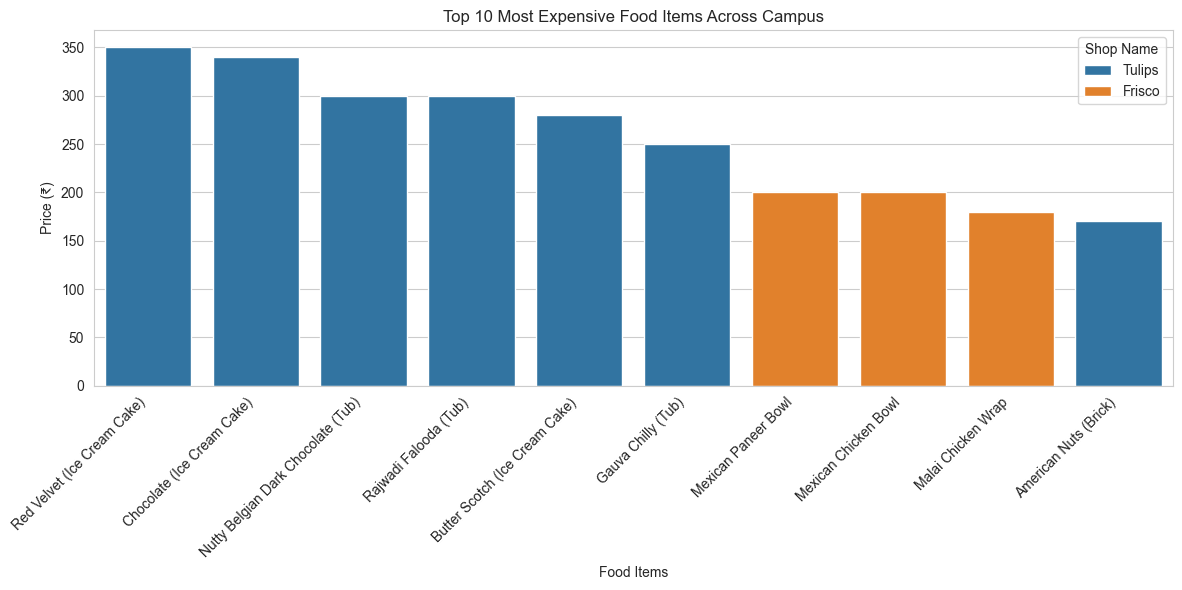

In [11]:
# Find the 10 most expensive food items across campus

expensive_items = df.sort_values(
    by="Price",
    ascending=False
).head(10)

print("Top 10 Most Expensive Food Items:")
display(expensive_items)

# Visualize the most expensive items

plt.figure(figsize=(12, 6))

sns.barplot(
    data=expensive_items,
    x="Item to Buy",
    y="Price",
    hue="Shop Name",
    dodge=False
)

plt.title("Top 10 Most Expensive Food Items Across Campus")
plt.xlabel("Food Items")
plt.ylabel("Price (₹)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()